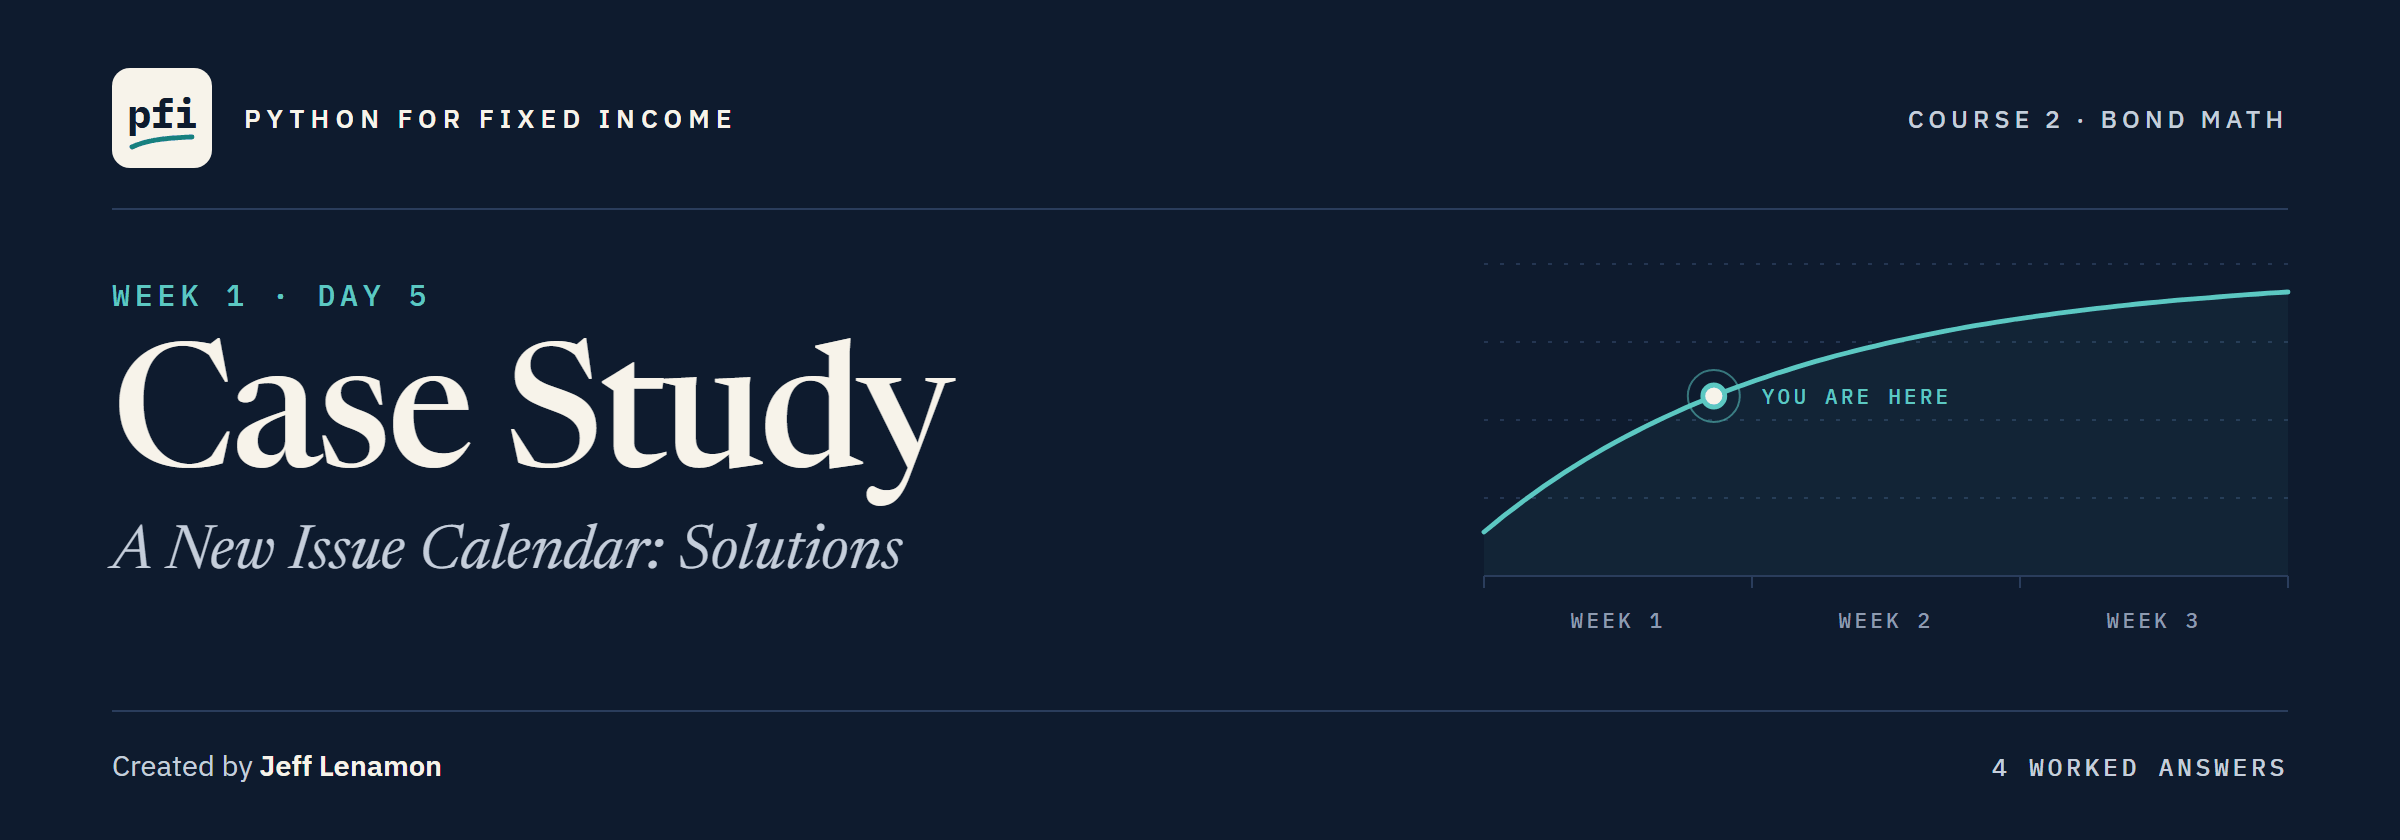

# Case Study: A New Issue Calendar: Solutions

Week 1, Day 5. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day5/05_case_study_a_new_issue_calendar_solutions.ipynb)

## Exercises

Run the next cells first: the work folder with the module as this notebook leaves it, the imports, `check`, and the second calendar.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module and its tests as notebook 05 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(5, after=5)

Work folder pfi_course2_05_k4w7q2xr: 2 data files, the module as notebook 05 left it, 5 commits, tagged week1


In [2]:
import importlib

import pandas as pd

import bondmath
print(bondmath.price_from_yield(5.5, 5.5, 10))

99.99999999999986


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [4]:
exercise_calendar = pd.DataFrame({
    'ticker': ['FESA', 'KRIN', 'DRAA', 'VYRE', 'NEVR'],
    'issuer': ['Feskundra Systems', 'Krilorin Logistics', 'Dralundra Brands', 'Vyrerone Metals',
               'Nevovar Energy'],
    'coupon_pct': [4.5, 6.25, 4.25, 7.25, 6.125],
    'years': [4, 7, 2, 8, 12],
    'reoffer_price': [99.85, 99.375, 100.0, 99.0, 99.625],
})
exercise_calendar

,ticker,issuer,coupon_pct,years,reoffer_price
0,FESA,Feskundra Systems,4.500,4,99.850
1,KRIN,Krilorin Logistics,6.250,7,99.375
2,DRAA,Dralundra Brands,4.250,2,100.000
3,VYRE,Vyrerone Metals,7.250,8,99.000
4,NEVR,Nevovar Energy,6.125,12,99.625


### Exercise 1

In [5]:
# one yield per issue, as in 5.1, then each gap over the coupon in bp; ex_cal is a shorter name
ex_cal = exercise_calendar
ex_cal['yield_pct'] = [bondmath.yield_from_price(c, p, t) for c, p, t in
                       zip(ex_cal['coupon_pct'], ex_cal['reoffer_price'], ex_cal['years'])]
ex_cal['gap_bp'] = (ex_cal['yield_pct'] - ex_cal['coupon_pct']) * 100
print(ex_cal[['ticker', 'yield_pct', 'gap_bp']].round(4))
ex1_nevovar = ex_cal.loc[ex_cal['ticker'] == 'NEVR', 'yield_pct'].iloc[0]
# idxmax gives the row label of the largest gap
ex1_widest = ex_cal.loc[ex_cal['gap_bp'].idxmax(), 'ticker']

  ticker  yield_pct   gap_bp
0   FESA     4.5414   4.1432
1   KRIN     6.3620  11.2028
2   DRAA     4.2500   0.0000
3   VYRE     7.4180  16.7976
4   NEVR     6.1697   4.4691


Vyrerone, 8 years a full point under 100, is furthest over its coupon; Dralundra, at 100, yields its coupon.

In [6]:
check('Exercise 1 Nevovar yield', ex1_nevovar, 6.169691301427065)
check('Exercise 1 furthest over its coupon', ex1_widest, 'VYRE')

Exercise 1 Nevovar yield: correct
Exercise 1 furthest over its coupon: correct


### Exercise 2

In [7]:
# each issue at 5.50 percent, then again with an eighth more coupon, as in 5.2 and 5.4
coupons, terms = ex_cal['coupon_pct'], ex_cal['years']
ex_cal['price_at_5_50'] = [bondmath.price_from_yield(c, 5.5, t) for c, t in zip(coupons, terms)]
ex_cal['step_value'] = [bondmath.price_from_yield(c + 0.125, 5.5, t)
                        - bondmath.price_from_yield(c, 5.5, t) for c, t in zip(coupons, terms)]
print(ex_cal[['ticker', 'years', 'price_at_5_50', 'step_value']].round(4))
ex2_krilorin = ex_cal.loc[ex_cal['ticker'] == 'KRIN', 'price_at_5_50'].iloc[0]
ex2_step_nevovar = ex_cal.loc[ex_cal['ticker'] == 'NEVR', 'step_value'].iloc[0]

  ticker  years  price_at_5_50  step_value
0   FESA      4        96.4528      0.4434
1   KRIN      7       104.3091      0.7182
2   DRAA      2        97.6629      0.2337
3   VYRE      8       111.2040      0.8003
4   NEVR     12       105.4377      1.0875


Krilorin's step equals Hulvimer's on the first calendar: same term, same yield, same step.

In [8]:
check('Exercise 2 Krilorin at 5.50', ex2_krilorin, 104.30912805092527)
check('Exercise 2 Nevovar step', ex2_step_nevovar, 1.0875497936428076)

Exercise 2 Krilorin at 5.50: correct
Exercise 2 Nevovar step: correct


### Exercise 3

In [9]:
%%writefile -a bondmath.py


def par_coupon_pct(yield_pct: float, step: float = 0.125) -> float:
    """The coupon on a grid of `step` that prices nearest par at yield_pct, on a coupon date.

    Units: yield_pct and step in percent; returns the coupon in percent.
    Convention: price is a straight line in the coupon and crosses 100 at the yield, so the grid
    coupon nearest the yield prices nearest par. A yield exactly halfway goes to the higher coupon.
    Raises ValueError unless yield_pct and step are above zero.
    Excel: =MROUND(yield_pct, step)
    """
    # stop on a yield or a step the rule does not cover
    if yield_pct <= 0 or step <= 0:
        raise ValueError(f"yield_pct and step must be above zero, not {yield_pct} and {step}")
    # count the steps, add a half, and keep the whole part: rounding half up
    whole_steps = int(yield_pct / step + 0.5)
    return whole_steps * step

Appending to bondmath.py


In [10]:
%%writefile -a test_bondmath.py


def test_par_coupon_pct_matches_excel_mround():
    # Excel's =MROUND(yield,0.125) of each yield; the last two are exact ties, which go up
    cases = [(5.43, 5.375), (5.69, 5.75), (9.08, 9.125), (4.55, 4.5), (5.0625, 5.125), (4.9375, 5.0)]
    for yield_pct, expected in cases:
        assert bondmath.par_coupon_pct(yield_pct) == pytest.approx(expected, abs=1e-12), yield_pct
    # a yield of zero has no coupon on the grid
    with pytest.raises(ValueError):
        bondmath.par_coupon_pct(0.0)

Appending to test_bondmath.py


In [11]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..............                                                           [100%]
14 passed in 0.50s



In [12]:
# the file changed, so read it again before calling the new function
importlib.reload(bondmath)
ex3_coupons = [bondmath.par_coupon_pct(y) for y in ex_cal['yield_pct']]
print(ex3_coupons)

[4.5, 6.375, 4.25, 7.375, 6.125]


Krilorin and Vyrerone move one eighth up; the other three keep their coupons.
`int()` drops the decimals, so adding a half first turns a remainder of a half or more into one more step.

In [13]:
check('Exercise 3 grid coupons', ex3_coupons, [4.5, 6.375, 4.25, 7.375, 6.125])

Exercise 3 grid coupons: correct


### Exercise 4: AI check

The function works per 1 of face: it turns the coupon into a decimal and pays back 1.
The docstring promises per 100, so Rulvolvey came back 1.073057, a hundredth of 107.3057.
The fix: keep the coupon per 100, `coupon_pct / frequency`, and pay back 100.

In [14]:
def assistant_price_from_yield(coupon_pct, yield_pct, years, frequency=2):
    """Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    On a coupon date there is no accrued interest, so this is both the clean and the dirty price.
    Excel: =-PV(yield_pct/100/frequency, frequency*years, coupon_pct/frequency, 100)
    """
    # the yield for one period as a decimal; the coupon for one period per 100 of face
    period_yield = yield_pct / 100 / frequency
    # the fix: the coupon stays per 100 of face, and the face back is 100
    period_coupon = coupon_pct / frequency
    periods = round(years * frequency)
    price = 0.0
    for k in range(1, periods + 1):
        # each coupon, and the face of 100 back with the last one
        amount = period_coupon + 100 if k == periods else period_coupon
        price += amount / (1 + period_yield) ** k
    return price

In [15]:
tvm = pd.read_csv('bondmath_excel_reference_tvm.csv')
rows = tvm[tvm['function'] == 'CALENDAR_PRICE']
# each row: Excel's PRICE of one issue at rate_pct, per 100 of face
for case, c, y, t, excel in zip(rows['case_id'], rows['coupon_pct'], rows['rate_pct'],
                                rows['years'], rows['excel_value']):
    result = assistant_price_from_yield(c, y, t)
    assert abs(result - excel) < 1e-6, f'{case}: {result:.6f} against Excel {excel:.6f}'
print(f'All {len(rows)} CALENDAR_PRICE rows match Excel')
ex4_rulvolvey = assistant_price_from_yield(6.0, 5.5, 30)
ex4_rows = len(rows)

All 21 CALENDAR_PRICE rows match Excel


Today's `test_price_falls_as_yield_rises` would not have caught it: prices a hundred times too small still fall as yields rise.
A test against Excel's numbers catches a unit error; a test of a rule may not.

In [16]:
check('Exercise 4 Rulvolvey', ex4_rulvolvey, 107.30566550271652)
check('Exercise 4 rows checked', ex4_rows, 21)

Exercise 4 Rulvolvey: correct
Exercise 4 rows checked: correct


[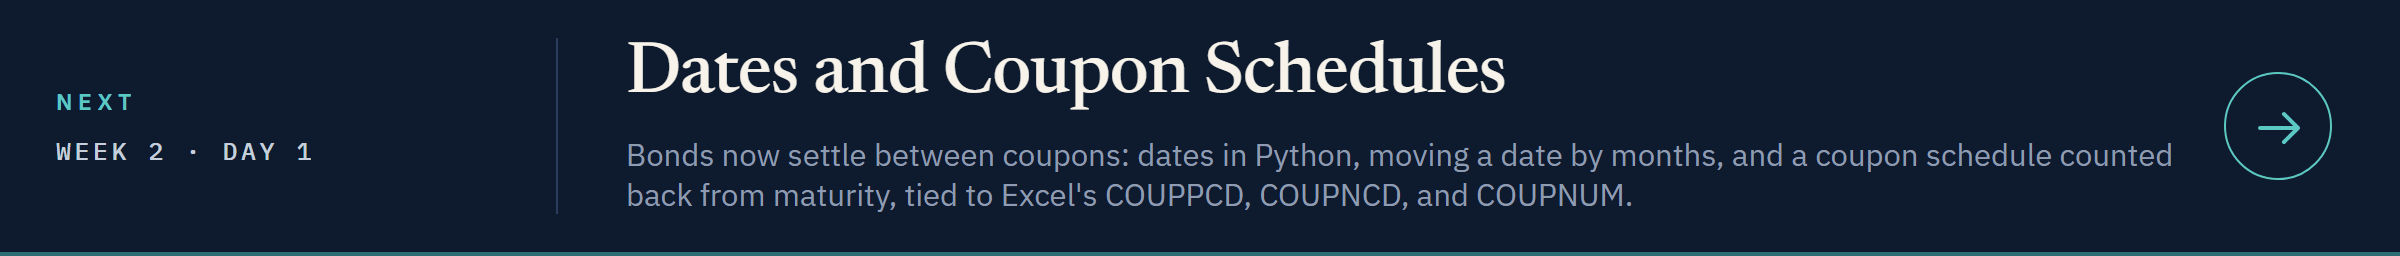](../../week2/day1/06_dates_and_coupon_schedules.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day1/06_dates_and_coupon_schedules.ipynb)